### BUSINESS UNDERSTANDING:

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
bm=pd.read_csv(filepath_or_buffer="bank_marketing_part1_Data.csv")
bm

,spending,advance_payments,probability_of_full_payment,current_balance,credit_limit,min_payment_amt,max_spent_in_single_shopping
0,19.94,16.92,0.8752,6.675,3.763,3.252,6.550
1,15.99,14.89,0.9064,5.363,3.582,3.336,5.144
2,18.95,16.42,0.8829,6.248,3.755,3.368,6.148
3,10.83,12.96,0.8099,5.278,2.641,5.182,5.185
4,17.99,15.86,0.8992,5.890,3.694,2.068,5.837
...,...,...,...,...,...,...,...
205,13.89,14.02,0.8880,5.439,3.199,3.986,4.738
206,16.77,15.62,0.8638,5.927,3.438,4.920,5.795
207,14.03,14.16,0.8796,5.438,3.201,1.717,5.001
208,16.12,15.00,0.9000,5.709,3.485,2.270,5.443


#### DATA UNDERSTANDING:

In [8]:
bm.dtypes

spending                        float64
advance_payments                float64
probability_of_full_payment     float64
current_balance                 float64
credit_limit                    float64
min_payment_amt                 float64
max_spent_in_single_shopping    float64
dtype: object

##### TO check empty cells:

In [9]:
bm.isna().sum() 

spending                        0
advance_payments                0
probability_of_full_payment     0
current_balance                 0
credit_limit                    0
min_payment_amt                 0
max_spent_in_single_shopping    0
dtype: int64

In [10]:
bm.describe()

,spending,advance_payments,probability_of_full_payment,current_balance,credit_limit,min_payment_amt,max_spent_in_single_shopping
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000


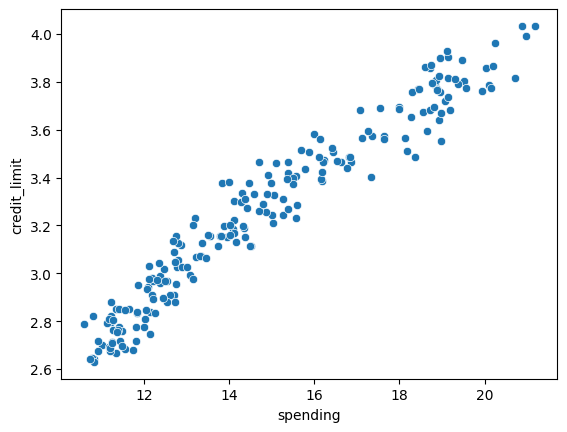

In [11]:
sn.scatterplot(data=bm,x='spending',y='credit_limit')
plt.show()

#### Note :
    1) There is no outlier presenting in this dataset.

#### DATA PREPARATION:

In [4]:
scaler=StandardScaler()
X_scaler=scaler.fit_transform(bm)
x_scaler=pd.DataFrame(data=X_scaler)
x_scaler

,0,1,2,3,4,5,6
0,1.754355,1.811968,0.178230,2.367533,1.338579,-0.298806,2.328998
1,0.393582,0.253840,1.501773,-0.600744,0.858236,-0.242805,-0.538582
2,1.413300,1.428192,0.504874,1.401485,1.317348,-0.221471,1.509107
3,-1.384034,-1.227533,-2.591878,-0.793049,-1.639017,0.987884,-0.454961
4,1.082581,0.998364,1.196340,0.591544,1.155464,-1.088154,0.874813
...,...,...,...,...,...,...,...
205,-0.329866,-0.413929,0.721222,-0.428801,-0.158181,0.190536,-1.366631
206,0.662292,0.814152,-0.305372,0.675253,0.476084,0.813214,0.789153
207,-0.281636,-0.306472,0.364883,-0.431064,-0.152873,-1.322158,-0.830235
208,0.438367,0.338271,1.230277,0.182048,0.600814,-0.953484,0.071238


In [5]:
x_scaler.mean().round(),x_scaler.std().round()

(0    0.0
 1    0.0
 2    0.0
 3   -0.0
 4   -0.0
 5    0.0
 6   -0.0
 dtype: float64,
 0    1.0
 1    1.0
 2    1.0
 3    1.0
 4    1.0
 5    1.0
 6    1.0
 dtype: float64)

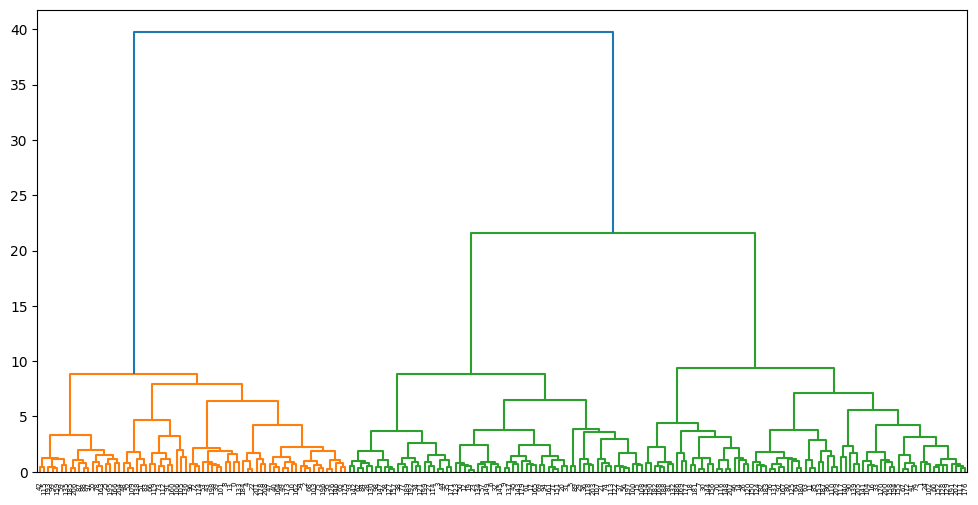

In [6]:
plt.figure(figsize=(12,6))
denogram=sch.dendrogram(sch.linkage(x_scaler,method='ward'))
plt.show()

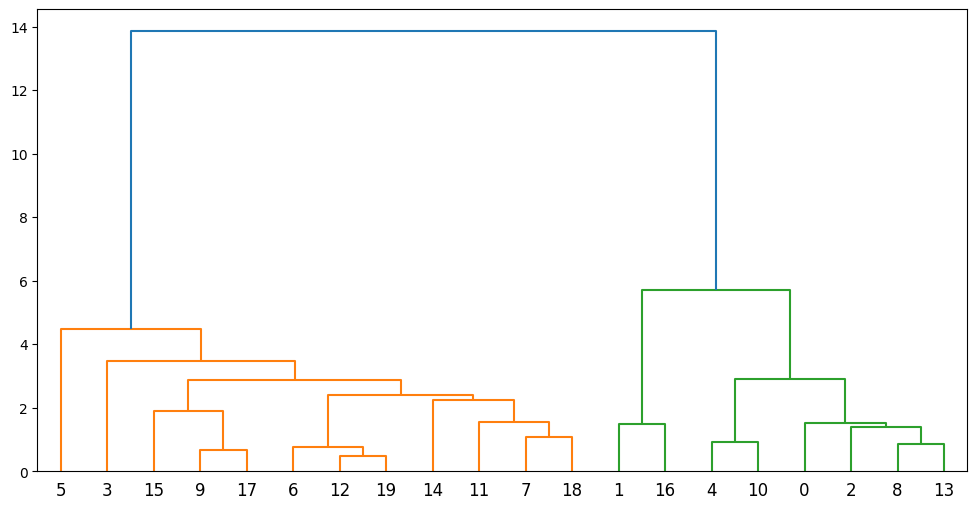

In [7]:
xt_scaler=x_scaler.head(20)
plt.figure(figsize=(12,6))
denogram=sch.dendrogram(sch.linkage(xt_scaler,method='ward'))
plt.show()

#### Apply K-means clusterig:

In [8]:
wcss = []
silhouette_scores = []

for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, random_state=25, n_init=10)
    labels = kmeans.fit_predict(x_scaler)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(x_scaler, labels))


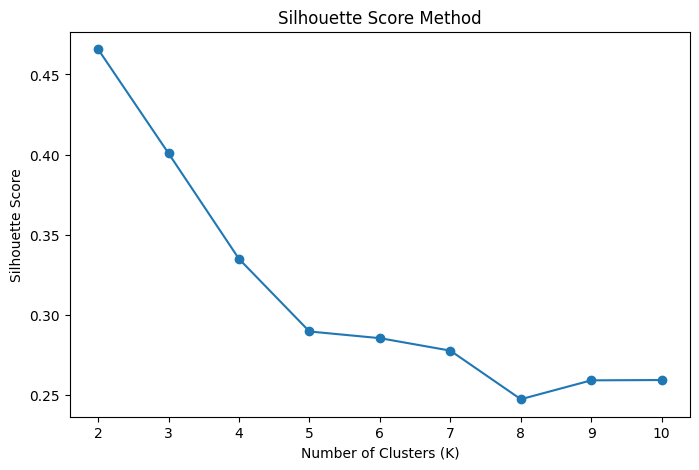

In [9]:

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Method")
plt.show()

In [14]:
best_k = range(2, 11)[silhouette_scores.index(max(silhouette_scores))]

print("Best number of clusters:", best_k)
print("Highest Silhouette Score:", max(silhouette_scores))

Best number of clusters: 2
Highest Silhouette Score: 0.46577247686580914


#### Note :
     1)Elbow Method (WCSS): Helps identify a suitable number of clusters.
     2)Silhouette Score: A higher score generally indicates better-separated, more cohesive clusters.

#### Note:
Silhouette Score | Interpretation                                                                 |
| ---------------- | ------------------------------------------------------------------------------ |
| **0.71 to 1.00** | Excellent clustering                                                           |
| **0.51 to 0.70** | Good clustering                                                                |
| **0.26 to 0.50** | Weak or moderate clustering                                                    |
| **0.00 to 0.25** | Poor clustering; clusters may overlap                                          |
| **Less than 0**  | Likely incorrect clustering; data points may be assigned to the wrong clusters |


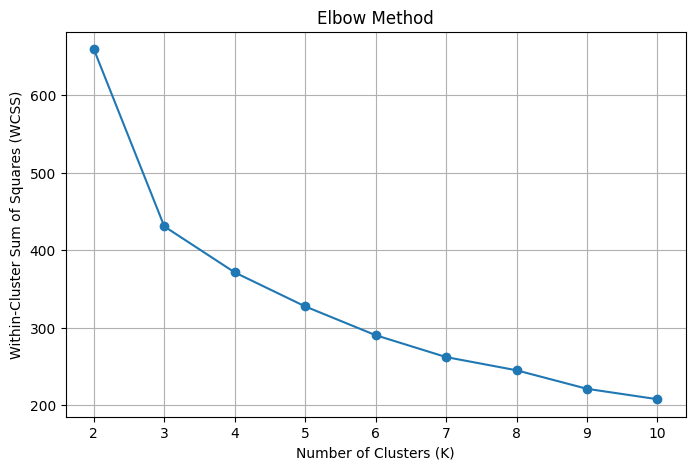

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11),wcss,marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [12]:
best_k = 2  

final_kmeans = KMeans(n_clusters=best_k,random_state=25,n_init=10)

bm['Cluster'] = final_kmeans.fit_predict(x_scaler)

bm.head()

,spending,advance_payments,probability_of_full_payment,current_balance,credit_limit,min_payment_amt,max_spent_in_single_shopping,Cluster
0,19.94,16.92,0.8752,6.675,3.763,3.252,6.550,1
1,15.99,14.89,0.9064,5.363,3.582,3.336,5.144,0
2,18.95,16.42,0.8829,6.248,3.755,3.368,6.148,1
3,10.83,12.96,0.8099,5.278,2.641,5.182,5.185,0
4,17.99,15.86,0.8992,5.890,3.694,2.068,5.837,1


In [13]:
cluster_profile = bm.groupby('Cluster').mean().round(3)

cluster_profile

,spending,advance_payments,probability_of_full_payment,current_balance,credit_limit,min_payment_amt,max_spent_in_single_shopping
Cluster,,,,,,,
0,12.931,13.693,0.864,5.340,3.026,3.827,5.082
1,18.159,16.055,0.884,6.127,3.661,3.480,5.972
